# Paso 7 · Incertidumbre y templates (con Python)

Notebook del **Paso 7**: una familia de plantas, el *template* en cada frecuencia y cómo el controlador lo traslada.

| Concepto matemático | Concepto de programación |
|---|---|
| familia $P(s)=\frac{K}{s(s+a)}$, $K\in[1,5]$, $a\in[1,3]$ | rejillas con `np.linspace` / `np.meshgrid` |
| template $\mathcal P(\omega)=\{P_i(j\omega)\}$ | comprensión de listas, arrays complejos |
| el borde de la caja de parámetros | construcción de un camino cerrado de puntos |
| el controlador traslada el template | multiplicación compleja = suma en (fase, dB) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
from nbhelp import db, wrapfase, poligono, AZUL, NARANJA, TINTA, GRIS, VERDE, MORADO
from qft import KS, AS, P, P0, family, template, edge_params   # el módulo qft.py de la raíz del curso
print("K de", KS[0], "a", KS[-1], "->", len(KS), "valores;  a de", AS[0], "a", AS[-1], "->", len(AS), "valores;  plantas:", len(KS)*len(AS))

K de 1.0 a 5.0 -> 17 valores;  a de 1.0 a 3.0 -> 13 valores;  plantas: 221


## 1. Por qué incertidumbre, y la familia

Los parámetros reales no se conocen con exactitud: aquí $K\in[1,5]$ y $a\in[1,3]$. Tomamos una rejilla de $17\times13=221$ plantas; el **nominal** $P_0$ es $(K,a)=(1,1)$, una esquina de la caja de parámetros.

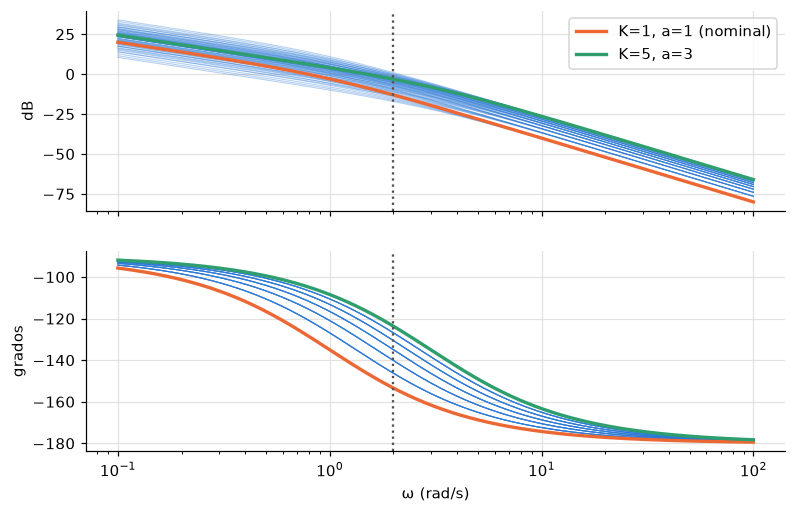

In [3]:
w = np.logspace(-1, 2, 600)
fig, (m, p) = plt.subplots(2, 1, figsize=(8.2, 5.2), sharex=True)
for K in KS[::2]:
    for a in AS[::2]:
        z = P(w, K, a); m.semilogx(w, db(z), color=AZUL, lw=0.7, alpha=0.35); p.semilogx(w, np.degrees(np.unwrap(np.angle(z))), color=AZUL, lw=0.7, alpha=0.35)
for (K, a, c, lab) in [(1, 1, NARANJA, "K=1, a=1 (nominal)"), (5, 3, VERDE, "K=5, a=3")]:
    z = P(w, K, a); m.semilogx(w, db(z), color=c, lw=2.2, label=lab); p.semilogx(w, np.degrees(np.unwrap(np.angle(z))), color=c, lw=2.2)
m.axvline(2, ls=":", color=GRIS); p.axvline(2, ls=":", color=GRIS); m.legend(); m.set_ylabel("dB"); p.set_ylabel("grados"); p.set_xlabel("ω (rad/s)")
plt.show()

## 2. En una frecuencia, cada planta es un punto del mapa

A $\omega=2$ calculamos las cuatro esquinas de la caja de parámetros $(K,a)$:

In [4]:
w0 = 2.0
esquinas = [(1, 1), (1, 3), (5, 1), (5, 3)]
print(f"{'(K,a)':>8} {'|P(j2)| dB':>12} {'fase':>9}")
for K, a in esquinas:
    z = P(w0, K, a); print(f"{str((K,a)):>8} {db(z):>12.2f} {float(wrapfase(z)):>8.1f}°")

   (K,a)   |P(j2)| dB      fase
  (1, 1)       -13.01   -153.4°
  (1, 3)       -17.16   -123.7°
  (5, 1)         0.97   -153.4°
  (5, 3)        -3.18   -123.7°


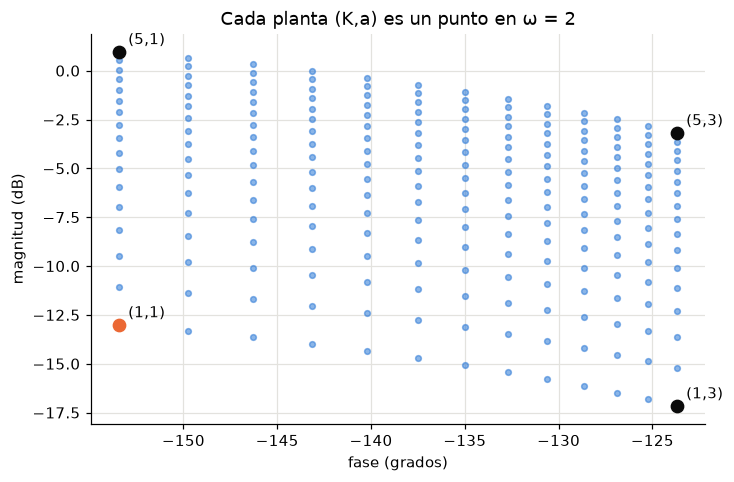

In [5]:
KK, AA = np.meshgrid(KS, AS); nube = P(w0, KK.ravel(), AA.ravel())
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.scatter(wrapfase(nube), db(nube), s=14, color=AZUL, alpha=0.55)
for K, a in esquinas:
    z = P(w0, K, a); ax.plot(wrapfase(z), db(z), "o", color=NARANJA if (K, a) == (1, 1) else TINTA, ms=8)
    ax.annotate(f"({K},{a})", (wrapfase(z), db(z)), xytext=(6, 5), textcoords="offset points")
ax.set_xlabel("fase (grados)"); ax.set_ylabel("magnitud (dB)"); ax.set_title("Cada planta (K,a) es un punto en ω = 2"); plt.show()

## 3. Definición: el template

$$\mathcal P(\omega)=\{\,P(j\omega;\theta):\ \theta\in\Theta\,\}\subset\mathbb C.$$

En el plano (fase, dB) es una región. Para dibujarla basta su **borde**, que viene del borde de la caja de parámetros (Paso 16 comprueba cuándo esto vale):

160 puntos del borde; primeros: [(1.0, 1), (1.1, 1), (1.21, 1)] ...


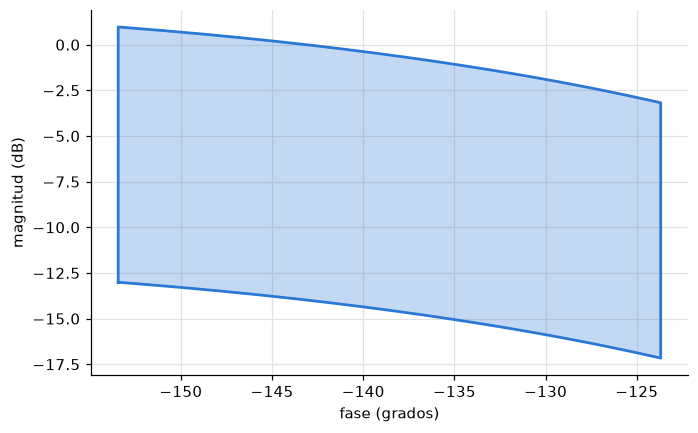

anchura en fase: 29.7°   altura en dB: 18.1 dB


In [6]:
e = edge_params()                                        # recorre el perímetro de la caja (K,a): 4 lados
print(len(e), "puntos del borde; primeros:", [(round(float(k), 2), a) for k, a in e[:3]], "...")
zb = template(2.0)                                       # P_i(j2) en esos puntos
fig, ax = plt.subplots(figsize=(7, 4.3)); poligono(ax, zb, AZUL)
ax.set_xlabel("fase (grados)"); ax.set_ylabel("magnitud (dB)"); plt.show()
print(f"anchura en fase: {np.ptp(wrapfase(zb)):.1f}°   altura en dB: {np.ptp(db(zb)):.1f} dB")

## 4. Los templates cambian con la frecuencia

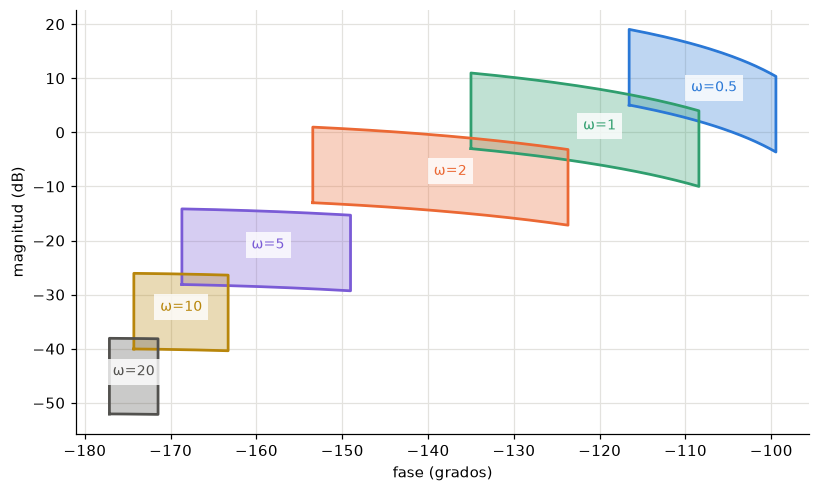

    ω  ancho fase   alto dB
  0.5       17.1°     22.7
    1       26.6°     21.0
    2       29.7°     18.1
    5       19.7°     15.1
   10       11.0°     14.3
   20        5.7°     14.1


In [7]:
fig, ax = plt.subplots(figsize=(8.6, 5))
cols = [AZUL, VERDE, NARANJA, MORADO, "#b8860b", GRIS]
for wv, c in zip((0.5, 1, 2, 5, 10, 20), cols):
    z = template(wv); poligono(ax, z, c, alpha=0.3)
    ax.text(wrapfase(z).mean(), db(z).mean(), f"ω={wv:g}", color=c, ha="center", va="center", fontsize=9, bbox=dict(fc="white", ec="none", alpha=0.8))
ax.set_xlabel("fase (grados)"); ax.set_ylabel("magnitud (dB)"); plt.show()
print(f"{'ω':>5} {'ancho fase':>11} {'alto dB':>9}")
for wv in (0.5, 1, 2, 5, 10, 20):
    z = template(wv); print(f"{wv:>5g} {np.ptp(wrapfase(z)):>10.1f}° {np.ptp(db(z)):>8.1f}")

A baja frecuencia el template es ancho en dB (la ganancia $K$ domina) y a alta frecuencia se estrecha en fase: $\angle P\to-180^\circ$ para toda la familia, y la incertidumbre que queda es casi toda de ganancia.

## 5. El controlador traslada el template sin deformarlo

$L_i=G\,P_i$ ⇒ en (fase, dB) *todas* las plantas se desplazan lo mismo: $\angle G$ y $|G|_{\rm dB}$.

G(j2) = 7.04∠39.3°  = 16.9 dB


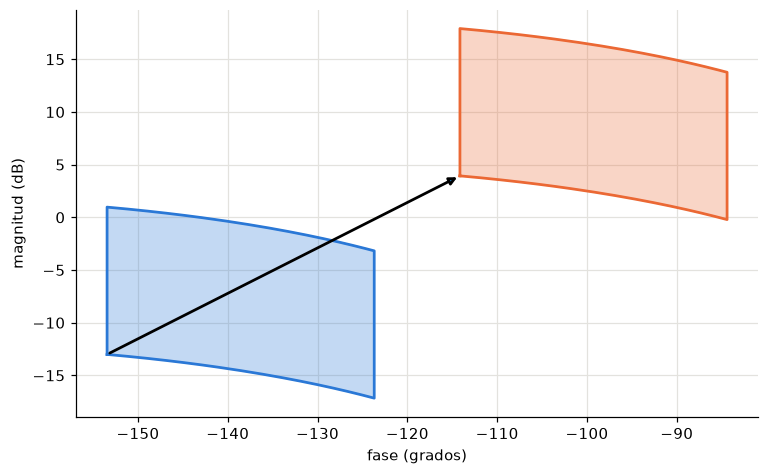

ancho del template: antes 29.74°/18.13 dB  después 29.74°/18.13 dB  (igual)


In [8]:
G = lambda w: 5 * (1 + 1j*w/2) / (1 + 1j*w/20)        # el compensador que diseñaremos en el paso 9
g = G(2.0); z = template(2.0)
print(f"G(j2) = {abs(g):.2f}∠{np.degrees(np.angle(g)):.1f}°  = {db(g):.1f} dB")
fig, ax = plt.subplots(figsize=(8, 4.8))
poligono(ax, z, AZUL); poligono(ax, z*g, NARANJA)
p0, l0 = P0(2.0), g*P0(2.0)
ax.annotate("", xy=(float(wrapfase(l0)), db(l0)), xytext=(float(wrapfase(p0)), db(p0)), arrowprops=dict(arrowstyle="-|>", lw=1.8))
ax.set_xlabel("fase (grados)"); ax.set_ylabel("magnitud (dB)"); plt.show()
print(f"ancho del template: antes {np.ptp(wrapfase(z)):.2f}°/{np.ptp(db(z)):.2f} dB  después {np.ptp(wrapfase(z*g)):.2f}°/{np.ptp(db(z*g)):.2f} dB  (igual)")

Moverlo es gratis; lo que no se puede es **achicarlo**. Por eso el diseño consiste en colocar el nominal $L_0$ donde, aun con todo el template alrededor, se cumplen las especificaciones (Paso 8).

## 6. Ejercicio del Paso 7

Con $P=\dfrac{K}{s(s+a)}$ y $\omega=2$:

1. $|P(j2)|$ en dB y $\angle P(j2)$ para $(K,a)=(1,1)$ y $(5,3)$.
2. Con esos dos puntos, ¿qué anchura tiene el template en fase y en dB?
3. Si $G(j2)=7.04\angle39.3^\circ$, ¿dónde queda el nominal $L_0=GP_0$?

**Tu turno.**

In [9]:
# 1) usa P(w, K, a)
# 2) diferencias entre los dos puntos
# 3) L0 = G P0 con G(j2) = 7.04∠39.3°
# escribe aquí tu código

In [10]:
for K, a in [(1, 1), (5, 3)]:
    z = P(2.0, K, a); print(f"(K,a) = ({K},{a}): {db(z):6.2f} dB, {float(wrapfase(z)):7.2f}°")
z1, z2 = P(2.0, 1, 1), P(2.0, 5, 3)
print(f"anchura entre esas dos esquinas: {abs(float(wrapfase(z2)) - float(wrapfase(z1))):.1f}° en fase, {db(z2) - db(z1):.2f} dB")
g = 7.04 * np.exp(1j * np.radians(39.3)); l0 = g * P(2.0, 1, 1)
print(f"L0 = G·P0 : {db(l0):.2f} dB, {float(wrapfase(l0)):.1f}°   (suma de dB y de fases: {db(g)+db(z1):.2f} dB, {np.degrees(np.angle(g))+float(wrapfase(z1)):.1f}°)")

(K,a) = (1,1): -13.01 dB, -153.43°
(K,a) = (5,3):  -3.18 dB, -123.69°
anchura entre esas dos esquinas: 29.7° en fase, 9.83 dB
L0 = G·P0 : 3.94 dB, -114.1°   (suma de dB y de fases: 3.94 dB, -114.1°)


## 7. Resumen

- Incertidumbre paramétrica ⇒ una **familia** de plantas; en cada $\omega$, un **template** (región) en el mapa (fase, dB).
- El template del borde de la caja basta para dibujarlo; cambia con $\omega$ (ancho en dB a baja frecuencia, estrecho en fase a alta).
- Un controlador **traslada** el template sin deformarlo.

**Siguiente:** Paso 8, especificaciones → *bounds*: en qué zona del mapa debe estar el nominal.